Notebook started morning July 11, 2025

# imports

In [ ]:
# jupyter setup boilerplate
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np


from fitting import *

import json
import datetime

from qualang_tools.plot import Fit

import pprint as pp

from plotting_helpers import *

%matplotlib inline
from pnax_msmts import *
from set_pulse_onoff import *
from malab import *

# Setting YOKO and DACs

In [3]:
pt = [ 1.5    ,    -0.26545701 , 3.19010634 , 0.59917512 , 0.64448126 , 0.80977877,
 -0.54189568 , 0.66401813 , 0.87285469]

print(pt)

drive_YOKO_and_DACs(pt)

[1.5, -0.26545701, 3.19010634, 0.59917512, 0.64448126, 0.80977877, -0.54189568, 0.66401813, 0.87285469]
Driving YOKO at (1.500) mA
Driving DAC at ( -0.265, 3.190, 0.599, 0.644,0.810, -0.542, 0.664, 0.873 ) mA


Flux line for qubit  0
Driving DAC at (-0.263) mA
old reading =  -0.151519775390625
target 127592
end of ramp - RAMP


Flux line for qubit  1
Driving DAC at (3.194) mA
old reading =  2.190093994140625
target 172885
end of ramp - None


Flux line for qubit  2
Driving DAC at (0.602) mA
old reading =  0.472564697265625
target 138925
end of ramp - RAMP


Flux line for qubit  3
Driving DAC at (0.647) mA
old reading =  0.52032470703125
target 139519
end of ramp - RAMP


Flux line for qubit  4
Driving DAC at (0.814) mA
old reading =  0.6601715087890625
target 141685
end of ramp - RAMP


Flux line for qubit  5
Driving DAC at (-0.533) mA
old reading =  -0.6946563720703125
target 123969
end of ramp - RAMP



Flux line for qubit  6
Driving DAC at (0.684) mA
old reading =  0.500259399414062

In [63]:
def hist(data=None, plot=True, ran=1.0):
    
    ig = data[0]
    qg = data[1]
    ie = data[2]
    qe = data[3]

    numbins = 200
    
    xg, yg = np.median(ig), np.median(qg)
    xe, ye = np.median(ie), np.median(qe)

    if plot==True:
        fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
        fig.tight_layout()

        axs[0].scatter(ig, qg, label='g', color='b', marker='*')
        axs[0].scatter(ie, qe, label='e', color='r', marker='*')
        axs[0].scatter(xg, yg, color='k', marker='o')
        axs[0].scatter(xe, ye, color='k', marker='o')
        axs[0].set_xlabel('I (a.u.)')
        axs[0].set_ylabel('Q (a.u.)')
        axs[0].legend(loc='upper right')
        axs[0].set_title('Unrotated')
        axs[0].axis('equal')
    """Compute the rotation angle"""
    theta = -np.arctan2((ye-yg),(xe-xg))
    """Rotate the IQ data"""
    ig_new = ig*np.cos(theta) - qg*np.sin(theta)
    qg_new = ig*np.sin(theta) + qg*np.cos(theta) 
    ie_new = ie*np.cos(theta) - qe*np.sin(theta)
    qe_new = ie*np.sin(theta) + qe*np.cos(theta)
    
    """New means of each blob"""
    xg, yg = np.median(ig_new), np.median(qg_new)
    xe, ye = np.median(ie_new), np.median(qe_new)
    
    #print(xg, xe)
    
    xlims = [xg-ran, xg+ran]
    ylims = [yg-ran, yg+ran]

    if plot==True:
        axs[1].scatter(ig_new, qg_new, label='g', color='b', marker='*')
        axs[1].scatter(ie_new, qe_new, label='e', color='r', marker='*')
        axs[1].scatter(xg, yg, color='k', marker='o')
        axs[1].scatter(xe, ye, color='k', marker='o')    
        axs[1].set_xlabel('I (a.u.)')
        axs[1].legend(loc='lower right')
        axs[1].set_title('Rotated')
        axs[1].axis('equal')

        """X and Y ranges for histogram"""
        
        ng, binsg, pg = axs[2].hist(ig_new, bins=numbins, range = xlims, color='b', label='g', alpha=0.5)
        ne, binse, pe = axs[2].hist(ie_new, bins=numbins, range = xlims, color='r', label='e', alpha=0.5)
        axs[2].set_xlabel('I(a.u.)')       
        
    else:        
        ng, binsg = np.histogram(ig_new, bins=numbins, range = xlims)
        ne, binse = np.histogram(ie_new, bins=numbins, range = xlims)

    """Compute the fidelity using overlap of the histograms"""
    contrast = np.abs(((np.cumsum(ng) - np.cumsum(ne)) / (0.5*ng.sum() + 0.5*ne.sum())))
    tind=contrast.argmax()
    threshold=binsg[tind]
    fid = contrast[tind]
    axs[2].set_title(f"Fidelity = {fid*100:.2f}%")

    return fid, threshold, theta


def fitdecaysin(xdata,ydata,fitparams=None,domain=None,showfit=False,showstartfit=False,label=""):
    """Fits decaying sin wave of form: p[0]*np.sin(2.*pi*p[1]*x+p[2]*pi/180.)*np.e**(-1.*(x-p[5])/p[3])+p[4]"""
    if domain is not None:
        fitdatax,fitdatay = selectdomain(xdata,ydata,domain)
    else:
        fitdatax=xdata
        fitdatay=ydata
    if fitparams is None:    
        FFT=scipy.fftpack.rfft(fitdatay)
        fft_freqs=scipy.fftpack.fftfreq(len(fitdatay),fitdatax[1]-fitdatax[0])
        max_ind=np.argmax(abs(FFT[4:int(len(fitdatay)/2)]))+4
        fft_val=FFT[max_ind]
        
        fitparams=[0,0,0,0,0]
        fitparams[4]=np.mean(fitdatay)
        fitparams[0]=(max(fitdatay)-min(fitdatay))/2.#2*abs(fft_val)/len(fitdatay)
        fitparams[1]=fft_freqs[max_ind]
        fitparams[2]=(cmath.phase(fft_val)-np.pi/2.)*180./np.pi
        fitparams[3]=(max(fitdatax)-min(fitdatax))
        print(fitparams)
        #fitparams[5]=fitdatax[0]
        
    decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] * np.pi / 180.) * np.e ** (
    -1. * (x - fitdatax[0]) / p[3]) + p[4]
    # decaysin3 = lambda p, x: p[0] * np.sin(2. * np.pi * p[1] * x + p[2] - np.pi / 2.) * np.e ** (
    # -1. * (x - fitdatax[0]) / p[3]) + p[4]
    #print "fitparams: ",fitparams
    p1 = fitgeneral(fitdatax, fitdatay, decaysin3, fitparams, domain=None, showfit=showfit, showstartfit=showstartfit,
                    label=label)
    return p1

# Troubleshooting

In [4]:
global_data_path = r"M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux"
expt_path = r"\qubit 0\troubleshoot 4.2 GHz"
global_data_path = global_data_path + expt_path 


 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00000_res_spec_ge_Q0_2025-07-11.h5
min amp at  6245.220406723022 MHz
{'f': [6245.350877657783, 0.014392914417986192],
 'fit_func': <function Fit.reflection_resonator_spectroscopy.<locals>.<lambda> at 0x0000020EAAC249D0>,
 'k': [0.632709964456956, 0.045189428534516414],
 'kc': [6.388235567285264, 0.020752053537600023],
 'ki': [-5.755525602828308, 0.02443737499691639],
 'offset': [44.754849583901105, 100.26386361218205],
 'slope': [-0.004977993122264953, -0.016045265672749987]}


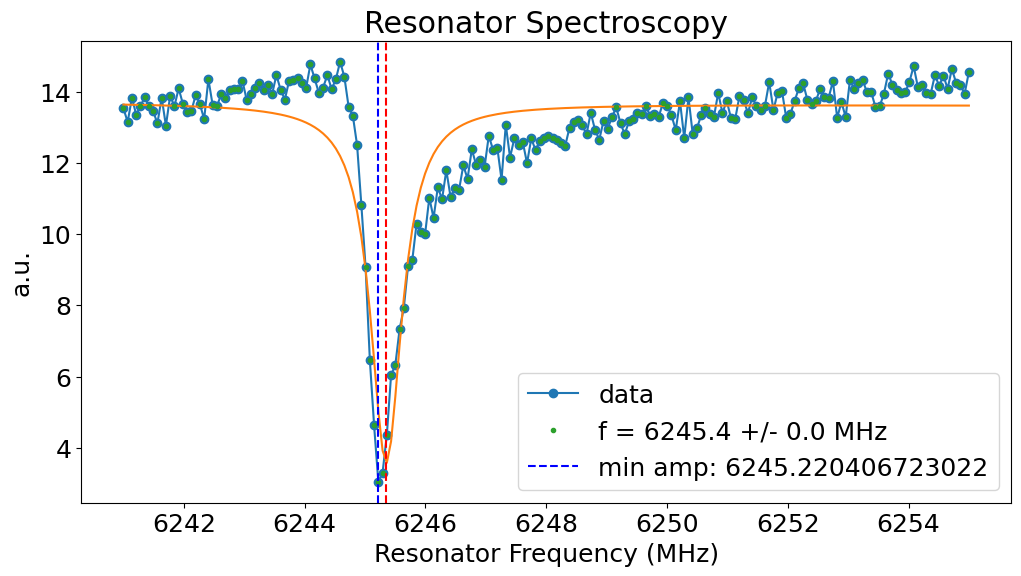

In [85]:
data = global_data_path + r"\00000_res_spec_ge_Q0_2025-07-11.h5"

with SlabFile(data, 'r') as f:
    freqs = array(f['fpts'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

# pp.pprint(config)

print('\n data path:', data)
plt.figure(figsize=(12,6))
plt.plot(freqs, amps, marker='o', label = 'data')
# plt.plot(freqs, y_fit, marker='', label = 'Fitted data')
plt.ylabel("a.u.")
plt.xlabel("Resonator Frequency (MHz)")
plt.title('Resonator Spectroscopy')
plt.legend()



fit = Fit()
fit_results = fit.reflection_resonator_spectroscopy(freqs, amps, plot=True)
plt.axvline(fit_results['f'][0], marker='', c='red', linestyle='--')
plt.axvline(freqs[np.argmin(amps)], marker='', c='blue', linestyle='--', label='min amp: ' + str(freqs[np.argmin(amps)]))
print('min amp at ', str(freqs[np.argmin(amps)]), 'MHz')
pp.pprint(fit_results)
plt.legend()

plt.show()


data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00004_qubit_spec_ge_Q0_2025-07-11.h5
{'flux_freq': 0,
 'flux_gain': 0,
 'flux_length': 0,
 'mixer_freq': 6000,
 'mux_ch': 4,
 'mux_ro_chs': [2, 3, 4, 5, 6, 7, 8, 9],
 'nqz_qubit': 1,
 'nqz_res': 2,
 'py_avg': 5,
 'qubit_ch': 0,
 'qubit_ch_ef': 0,
 'qubit_freq_ef': 0,
 'qubit_gain_ef': 0,
 'qubit_gain_ge': 0.2628786303461645,
 'qubit_length_ef': 25.0,
 'qubit_length_ge': 20,
 'qubit_phase': 0,
 'relax_delay': 100,
 'reps': 100,
 'res_ch': 1,
 'res_freq_ef': 0,
 'res_freq_ge': 6245.350877657783,
 'res_gain_ef': 0,
 'res_gain_ge': 0.001,
 'res_length_ef': 3,
 'res_length_ge': 3,
 'res_phase': 0,
 'ro_ch': 0,
 'ro_length': 3,
 'sigma_ef': 0,
 'sigma_ge': 0.01,
 'start': 4000.0,
 'steps': 500,
 'stop': 4400.0,
 't1': 0,
 't2': 0,
 'threshold': 0,
 'trig_time': 0.5}

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00004_qubit_spec_ge_Q0_2025-07-11.h5
{'

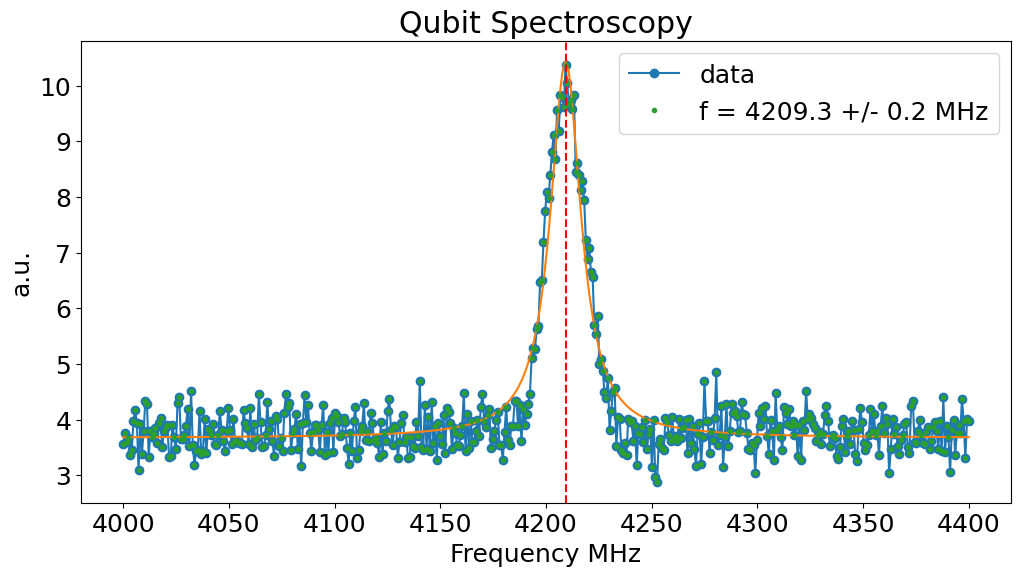

In [16]:
i = 0
data = global_data_path + r"\00004_qubit_spec_ge_Q0_2025-07-11.h5"
print('data path:', data)

SS = 'False' # did we do SingleShot for ge normalization?
ef = False # is this an ef experiment (is our single shot checking for ef?)
with SlabFile(data, 'r') as f:
    freqs = array(f['fpts'])[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
        if ef == True:
            If = array(f['I_f'])[0]
            Qf = array(f['Q_f'])[0]

pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
    if ef == True:
        f = np.mean((If+1j*Qf))
        pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
    ydata = pop_norm
else:
    ydata = amps

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(freqs, ydata, marker='o', label = 'data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel("Qubit Frequency (MHz)")
plt.title('Qubit Spectroscopy')
plt.legend()

fit = Fit()
fit_results = fit.transmission_resonator_spectroscopy(freqs, ydata, plot=True)
plt.axvline(fit_results['f'][0], marker='', c='red', linestyle='--')
# plt.plot(freqs,I)
# plt.plot(freqs,Q)
pp.pprint(fit_results)
# plt.axvline(4015)
plt.show()


{'expts': 300,
 'flux_freq': 0,
 'flux_gain': 0,
 'flux_length': 0,
 'mixer_freq': 6000,
 'mux_ch': 4,
 'mux_ro_chs': [2, 3, 4, 5, 6, 7, 8, 9],
 'nqz_qubit': 1,
 'nqz_res': 2,
 'py_avg': 5,
 'qubit_ch': 0,
 'qubit_ch_ef': 0,
 'qubit_freq_ef': 0,
 'qubit_freq_ge': 4202.5772901526,
 'qubit_gain_ef': 0,
 'qubit_gain_ge': 0.02,
 'qubit_length_ef': 25.0,
 'qubit_length_ge': 3.0100000000000002,
 'qubit_phase': 0,
 'relax_delay': 200,
 'reps': 500,
 'res_ch': 1,
 'res_freq_ef': 0,
 'res_freq_ge': 6245.350877657783,
 'res_gain_ef': 0,
 'res_gain_ge': 0.001,
 'res_length_ef': 3,
 'res_length_ge': 3,
 'res_phase': 0,
 'ro_ch': 0,
 'ro_length': 3,
 'sigma_ef': 0,
 'sigma_ge': 0.01,
 'start': 0.02,
 'step': 0.01,
 't1': 0,
 't2': 0,
 'threshold': 0,
 'trig_time': 0.5}

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00008_time_rabi_ge_Q0_2025-07-11.h5


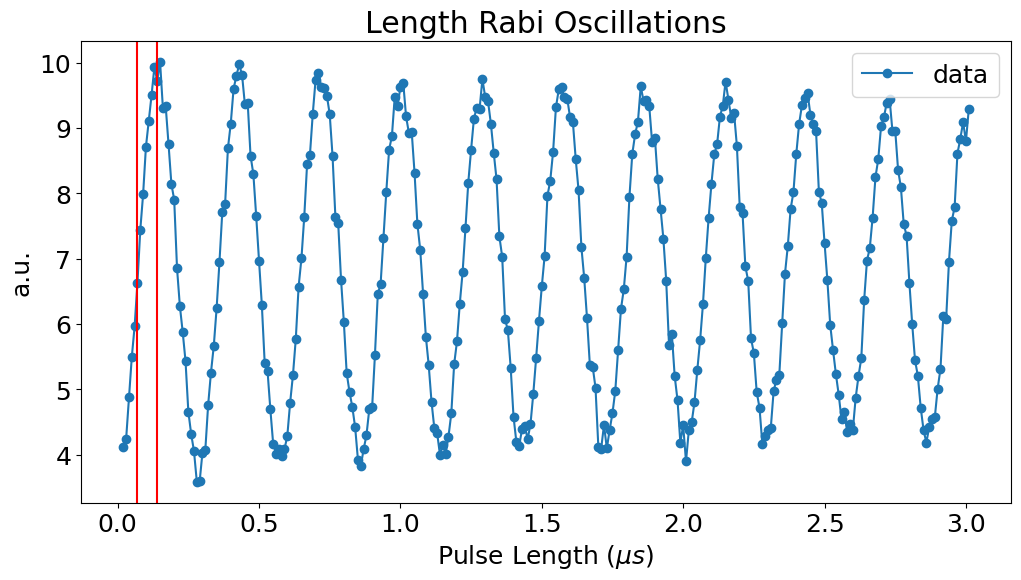

In [ ]:
data = global_data_path + r"\00009_time_rabi_ge_Q0_2025-07-11.h5"

SS = 'False' # did we do SingleShot for ge normalization?
ef = False # is this an ef experiment (is our single shot checking for ef?)
with SlabFile(data, 'r') as f:
    lengths = array(f['lengths'])[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
        if ef == True:
            If = array(f['I_f'])[0]
            Qf = array(f['Q_f'])[0]
pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
    if ef == True:
        f = np.mean((If+1j*Qf))
        pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
    ydata = pop_norm
else:
    ydata = amps

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(lengths, ydata,marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Pulse Length ($\mu s$)")
plt.title(r'Length Rabi Oscillations')
plt.legend()

# fit = Fit()
# fit_results = fit.rabi(gains, ydata, plot=True)
# pp.pprint(fit_results)
# peak = 0.5 / fit_results['f'][0] - (fit_results['phase'][0]/(180*fit_results['f'][0]))
# print('Peak:', peak)
# plt.axvline(peak, marker='', c='red')

# fit_results = fitdecaysin(lengths, ydata, showfit=True)
# pp.pprint(fit_results)
# peak = 0.5 / fit_results[1]
# print('Peak:', peak)
plt.axvline(0.14, marker='', c='red')
plt.axvline(0.14/2, marker='', c='red')


 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00004_power_rabi_ge_Q0_2025-07-11.h5
{'T': [-82592739.49120928, -157220990839551.9],
 'amp': [1.0356137109669605, 0.017690549294845776],
 'f': [6.361915592990217, 0.032180091607866],
 'fit_func': <function Fit.rabi.<locals>.<lambda> at 0x0000020EA9CFE160>,
 'offset': [0.012054009815644771, 0.011756874505116158],
 'phase': [3.182365989838498, 0.017592224363689447]}
Peak: 0.07859268056792795


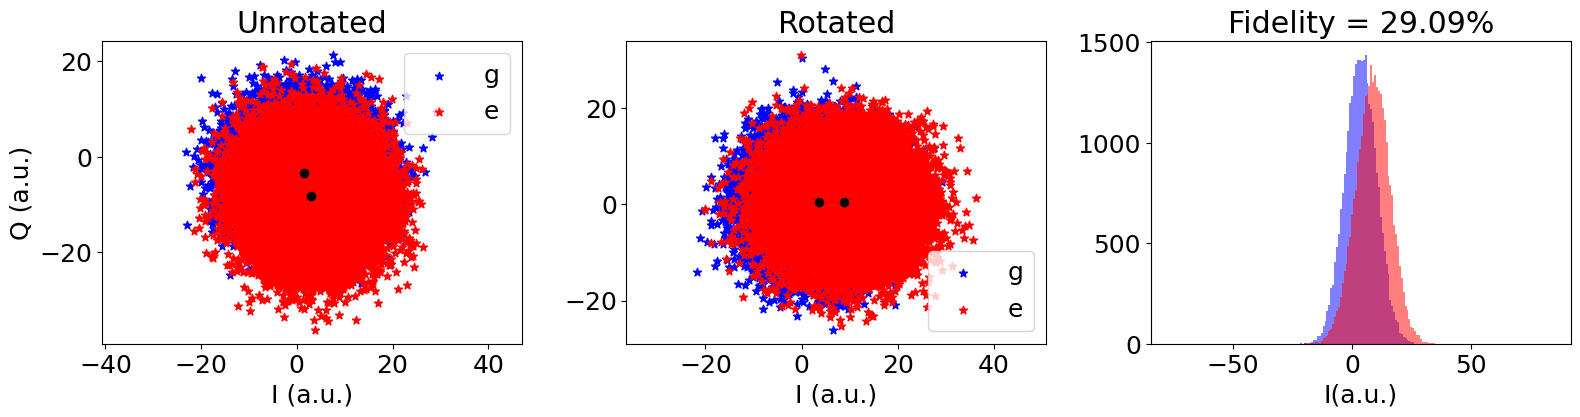

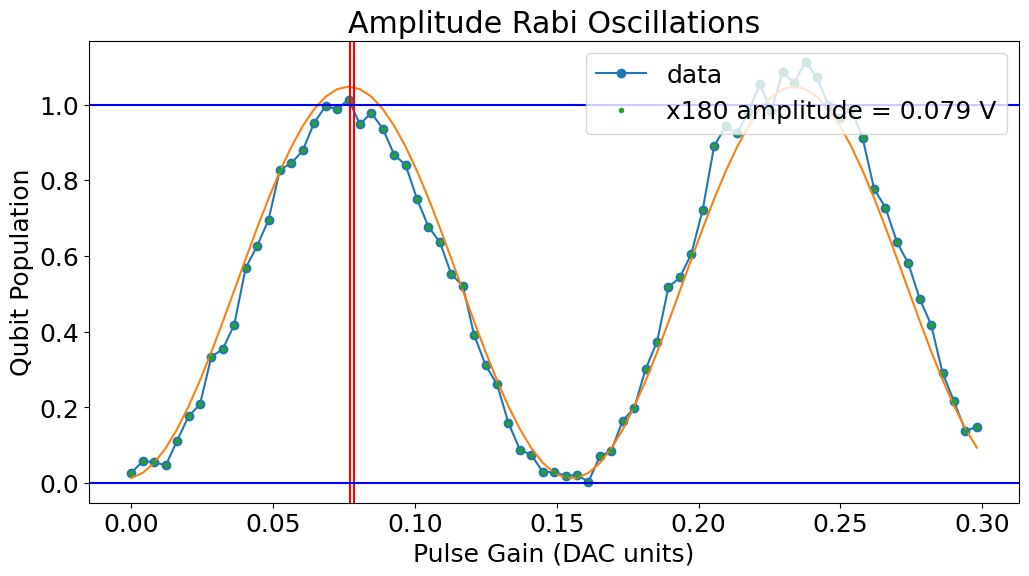

In [64]:

data = global_data_path + r"\00004_power_rabi_ge_Q0_2025-07-11.h5"

MUX = False
SS = 'True' # did we do SingleShot for ge normalization?
ef = False # is this an ef experiment (is our single shot checking for ef?)
with SlabFile(data, 'r') as f:
    gains = array(f['gains'])[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
        if ef == True:
            If = array(f['I_f'])[0]
            Qf = array(f['Q_f'])[0]
    fid, threshold, angle = hist(data=[Ig, Qg, Ie, Qe],  plot=True, ran=80)
# pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e - g) / abs(e - g)**2)
    if ef == True:
        f = np.mean((If+1j*Qf))
        pop_norm = abs(((I+1j*Q) - e)*(f - e) / abs(f - e)**2)
    ydata = pop_norm
else:
    ydata = amps

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(gains, ydata,marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Pulse Gain (DAC units)")
plt.title(r'Amplitude Rabi Oscillations')
plt.legend()

cor = 0.00

fit = Fit()
if MUX:
    ydata = ydata.T[0]

fit_results = fit.rabi(gains, ydata, plot=True)

pp.pprint(fit_results)
peak = 0.5 / fit_results['f'][0] #- (fit_results['phase'][0]/(180*fit_results['f'][0]))
# peak = fit_results['T'][0]
print('Peak:', peak + cor)
plt.axvline(peak + cor, marker='', c='red')

# plt.plot(gains, I,marker='o', label='I')
# plt.plot(gains, Q,marker='o', label='Q')

# plt.legend()
# fit_results = fitdecaysin(gains, ydata, showfit=True)
# # pp.pprint(fit_results)
# peak = 0.5 / fit_results[1]
# print('Peak:', peak + cor)
# plt.axvline(peak + cor, marker='', c='red')
# # plt.axvline(0.45, marker='', c='red')
# plt.show()
plt.axvline(0.077, marker='', c='red')
plt.axhline(0.0, marker='', c='b')
plt.axhline(1, marker='', c='b')


data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00007_Ramsey_ge_Q0_2025-07-11.h5

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00007_Ramsey_ge_Q0_2025-07-11.h5
qubit frequency [MHz] 4202.5772901526
ramsey diff [MHz] -1.8306283817006914
new qubit freq 4200.746661770899


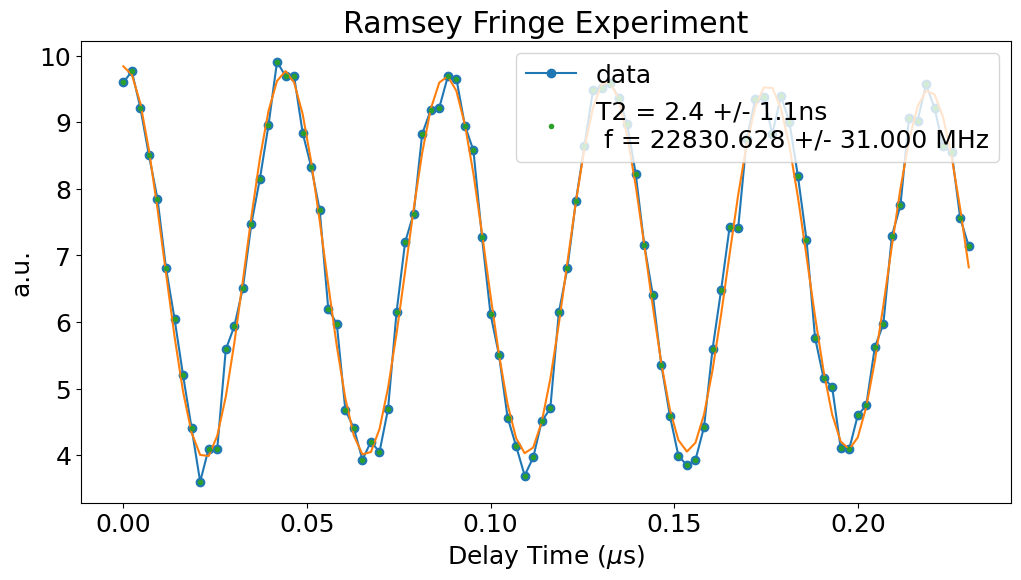

In [47]:
data = global_data_path + r"\00007_Ramsey_ge_Q0_2025-07-11.h5"

print('data path:', data)

MUX = False
SS = 'False'
ef = False # is this an ef experiment (is our single shot checking for ef?)
with SlabFile(data, 'r') as f:
    delay_times = array(f['delay_times'])[0]
    delay_times -= delay_times[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
        if ef == True:
            If = array(f['I_f'])[0]
            Qf = array(f['Q_f'])[0]
# pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
    if ef == True:
        f = np.mean((If+1j*Qf))
        pop_norm = abs(((I+1j*Q) - e)*(f- e) / abs(f - e)**2)
    ydata = pop_norm
else:
    ydata = amps

if MUX:
    ydata = ydata.T[0]

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(delay_times, ydata,marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Delay Time ($\mu$s)")
plt.title(r'Ramsey Fringe Experiment')
plt.legend()

fit = Fit()
fit_results = fit.ramsey(delay_times, ydata, plot=True)
# pp.pprint(fit_results)
print('qubit frequency [MHz]', config['qubit_freq_ge'])
print('ramsey diff [MHz]', (config['ramsey_freq']-fit_results['f'][0]))
print('new qubit freq', config['qubit_freq_ge']+(config['ramsey_freq']-fit_results['f'][0]))


In [43]:
4202.772901526+(21000-22830.628)/1000

4200.9422735260005

In [45]:
config['qubit_freq_ge']

4204.603529526

data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00011_Ramsey_ge_Q0_2025-07-11.h5

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00011_Ramsey_ge_Q0_2025-07-11.h5
qubit frequency [MHz] 4200.785086397594
ramsey diff [MHz] -0.025653967109647624
new qubit freq 4200.759432430484


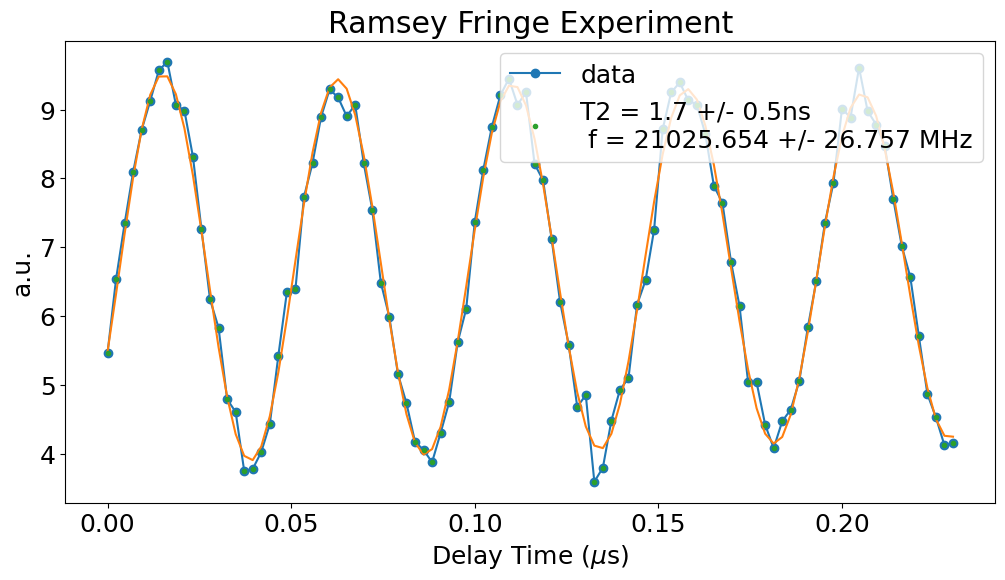

In [55]:
data = global_data_path + r"\00011_Ramsey_ge_Q0_2025-07-11.h5"

print('data path:', data)

MUX = False
SS = 'False'
ef = False # is this an ef experiment (is our single shot checking for ef?)
with SlabFile(data, 'r') as f:
    delay_times = array(f['delay_times'])[0]
    delay_times -= delay_times[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
        if ef == True:
            If = array(f['I_f'])[0]
            Qf = array(f['Q_f'])[0]
# pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
    if ef == True:
        f = np.mean((If+1j*Qf))
        pop_norm = abs(((I+1j*Q) - e)*(f- e) / abs(f - e)**2)
    ydata = pop_norm
else:
    ydata = amps

if MUX:
    ydata = ydata.T[0]

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(delay_times, ydata,marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Delay Time ($\mu$s)")
plt.title(r'Ramsey Fringe Experiment')
plt.legend()

fit = Fit()
fit_results = fit.ramsey(delay_times, ydata, plot=True)
# pp.pprint(fit_results)

print('qubit frequency [MHz]', config['qubit_freq_ge'])
print('ramsey diff [MHz]', (config['ramsey_freq']-fit_results['f'][0]))
print('new qubit freq', config['qubit_freq_ge']+(config['ramsey_freq']-fit_results['f'][0]))


{'flux_freq': 0,
 'flux_gain': 0,
 'flux_length': 0,
 'mixer_freq': 6000,
 'mux_ch': 4,
 'mux_ro_chs': [2, 3, 4, 5, 6, 7, 8, 9],
 'nqz_qubit': 1,
 'nqz_res': 2,
 'py_avg': 5,
 'qubit_ch': 0,
 'qubit_ch_ef': 0,
 'qubit_freq_ef': 0,
 'qubit_freq_ge': 4201.652184855204,
 'qubit_gain_ef': 0,
 'qubit_gain_ge': 0.2295880809677961,
 'qubit_length_ef': 25.0,
 'qubit_length_ge': 20,
 'qubit_phase': 0,
 'ramsey_freq': 1,
 'relax_delay': 500,
 'reps': 200,
 'res_ch': 1,
 'res_freq_ef': 0,
 'res_freq_ge': 6245.337469099564,
 'res_gain_ef': 0,
 'res_gain_ge': 0.001,
 'res_length_ef': 3,
 'res_length_ge': 3,
 'res_phase': 0,
 'ro_ch': 0,
 'ro_length': 3,
 'sigma_ef': 0,
 'sigma_ge': 0.01,
 'start': 0.0,
 'steps': 150,
 'stop': 5,
 't1': 0,
 't2': 0,
 'threshold': 0,
 'trig_time': 0.5}

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\single qubit characterization\00000_SpinEcho_ge_Q0_2025-07-02.h5
{'T2': [2.951709841470745, 0.12702677220895037],
 'amp': [6.426301395831975, 0

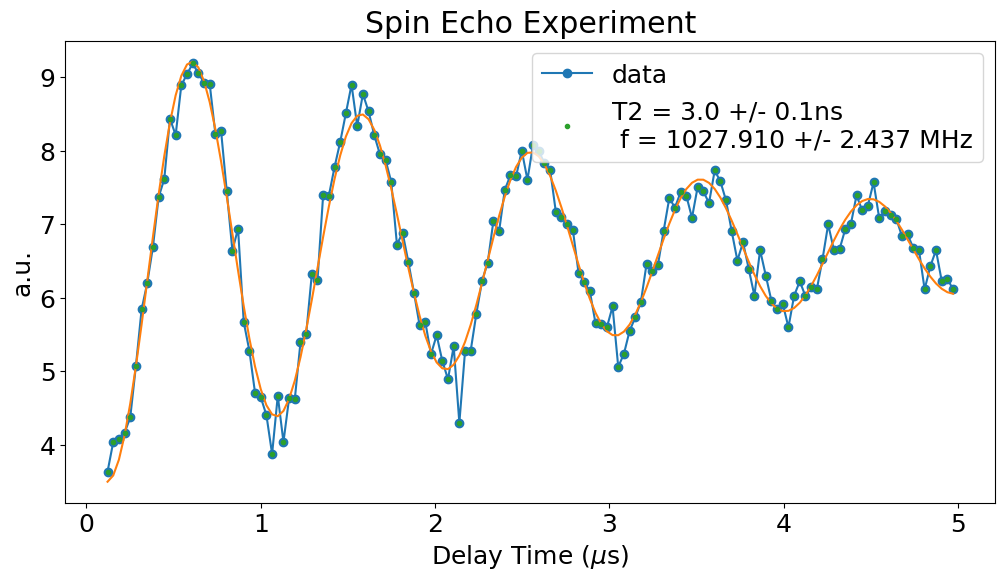

In [ ]:
data = global_data_path + r"\00000_SpinEcho_ge_Q0_2025-07-02.h5"
SS = True
with SlabFile(data, 'r') as f:
    delay_times1 = array(f['delay_times1'])[0]
    delay_times2 = array(f['delay_times2'])[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)

    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
pp.pprint(config)

if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
    ydata = pop_norm
else:
    ydata = amps

delay_times = delay_times1 + delay_times2

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(delay_times, ydata,marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Delay Time ($\mu$s)")
plt.title(r'Spin Echo Experiment')
plt.legend()

fit = Fit()
fit_results = fit.ramsey(delay_times, ydata, plot=True)
pp.pprint(fit_results)


M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\single qubit characterization\00000_T1_ge_Q0_2025-07-02.h5
{'flux_freq': 0,
 'flux_gain': 0,
 'flux_length': 0,
 'mixer_freq': 6000,
 'mux_ch': 4,
 'mux_ro_chs': [2, 3, 4, 5, 6, 7, 8, 9],
 'nqz_qubit': 1,
 'nqz_res': 2,
 'py_avg': 10,
 'qubit_ch': 0,
 'qubit_ch_ef': 0,
 'qubit_freq_ef': 0,
 'qubit_freq_ge': 4201.652184855204,
 'qubit_gain_ef': 0,
 'qubit_gain_ge': 0.2295880809677961,
 'qubit_length_ef': 25.0,
 'qubit_length_ge': 20,
 'qubit_phase': 0,
 'relax_delay': 200,
 'reps': 200,
 'res_ch': 1,
 'res_freq_ef': 0,
 'res_freq_ge': 6245.337469099564,
 'res_gain_ef': 0,
 'res_gain_ge': 0.001,
 'res_length_ef': 3,
 'res_length_ge': 3,
 'res_phase': 0,
 'ro_ch': 0,
 'ro_length': 3,
 'sigma_ef': 0,
 'sigma_ge': 0.01,
 'start': 0.0,
 'steps': 50,
 'stop': 150.0,
 't1': 0,
 't2': 0,
 'threshold': 0,
 'trig_time': 0.5}

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\single qubit characterization\00000_S

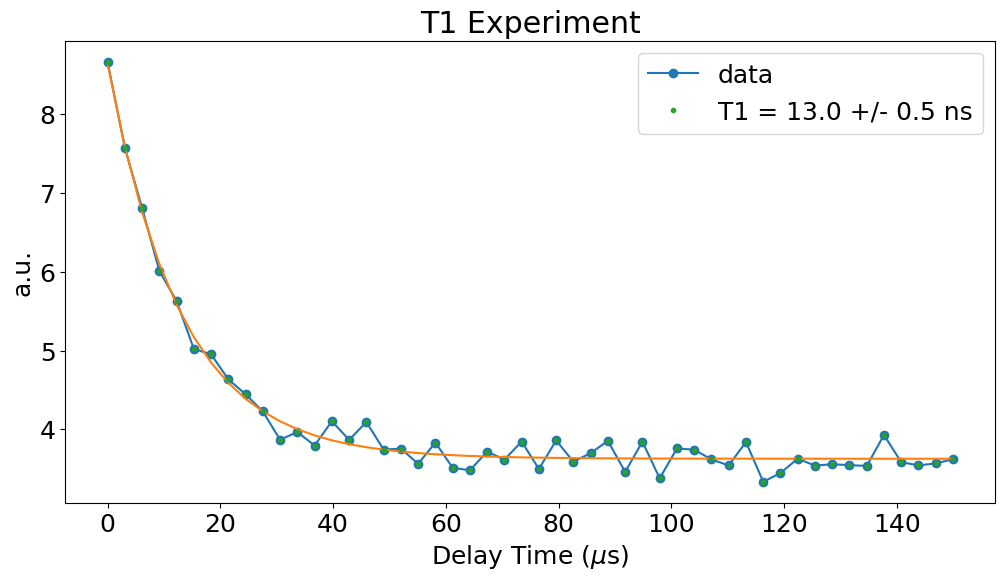

In [ ]:
data_path = global_data_path + r"\00000_T1_ge_Q0_2025-07-02.h5"
print(data_path)
SS = 'False'
MUX = False
with SlabFile(data_path, 'r') as f:
    delay_times = array(f['delay_times'])[0]
    I = array(f['avgi'])[0]
    Q = array(f['avgq'])[0]
    amps = array(f['amps'])[0]
    # fit_result = f.attrs['fit_result']
    # fit_result = json.loads(fit_result)
    config = f.attrs['config']
    config = json.loads(config)
    if SS == 'True':
        Ig = array(f['I_g'])[0]
        Qg = array(f['Q_g'])[0]
        Ie = array(f['I_e'])[0]
        Qe = array(f['Q_e'])[0]
pp.pprint(config)


if SS == 'True':
    # Normalize data
    e = np.mean((Ie+1j*Qe))
    g = np.mean((Ig+1j*Qg))
    ### Normalization ###
    pop_norm = abs(((I+1j*Q) - g)*(e- g) / abs(e - g)**2)
    ydata = pop_norm
else:
    ydata = amps

if MUX:
    ydata = ydata.T[0]

print('\n data path:', data)

plt.figure(figsize=(12,6))
plt.plot(delay_times, ydata, marker='o', label='data')
if SS == 'True':
    plt.ylabel("Qubit Population")
else:
    plt.ylabel("a.u.")
plt.xlabel(r"Delay Time ($\mu$s)")
plt.title(r'T1 Experiment')
plt.legend()

fit = Fit()
fit_results = fit.T1(delay_times, ydata, plot=True)
pp.pprint(fit_results)


{'SS_ONLY': 'True',
 'flux_freq': 0,
 'flux_gain': 0,
 'flux_length': 0,
 'mixer_freq': 6000,
 'mux_ch': 4,
 'mux_ro_chs': [2, 3, 4, 5, 6, 7, 8, 9],
 'nqz_qubit': 1,
 'nqz_res': 2,
 'py_avg': 1,
 'qubit_ch': 0,
 'qubit_ch_ef': 0,
 'qubit_freq_ef': 0,
 'qubit_freq_ge': 4200.785086397594,
 'qubit_gain_ef': 0,
 'qubit_gain_ge': 0.077,
 'qubit_length_ef': 25.0,
 'qubit_length_ge': 20,
 'qubit_phase': 0,
 'relax_delay': 300,
 'reps': 1,
 'res_ch': 1,
 'res_freq_ef': 0,
 'res_freq_ge': 6244.58,
 'res_gain_ef': 0,
 'res_gain_ge': 0.0035,
 'res_length_ef': 3,
 'res_length_ge': 3,
 'res_phase': 0,
 'ro_ch': 0,
 'ro_length': 3,
 'sigma_ef': 0,
 'sigma_ge': 0.028,
 'steps': 10000,
 't1': 0,
 't2': 0,
 'threshold': 0,
 'trig_time': 0.5}

 data path: M:/malab/_Data/PUR1D4/20250620 - cooldown 7/fast flux\qubit 0\troubleshoot 4.2 GHz\00010_IQ_plot_Q0_2025-07-11.h5


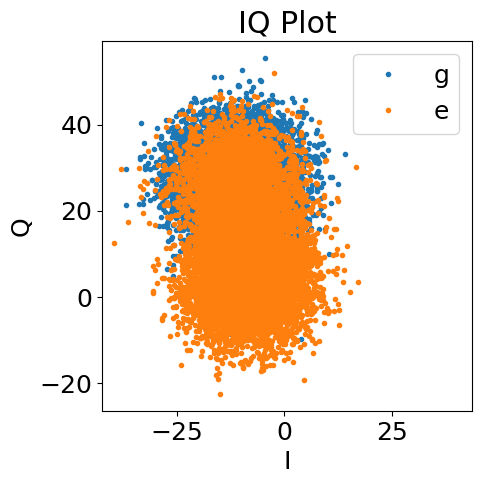

Optimal fidelity after rotation = 0.608


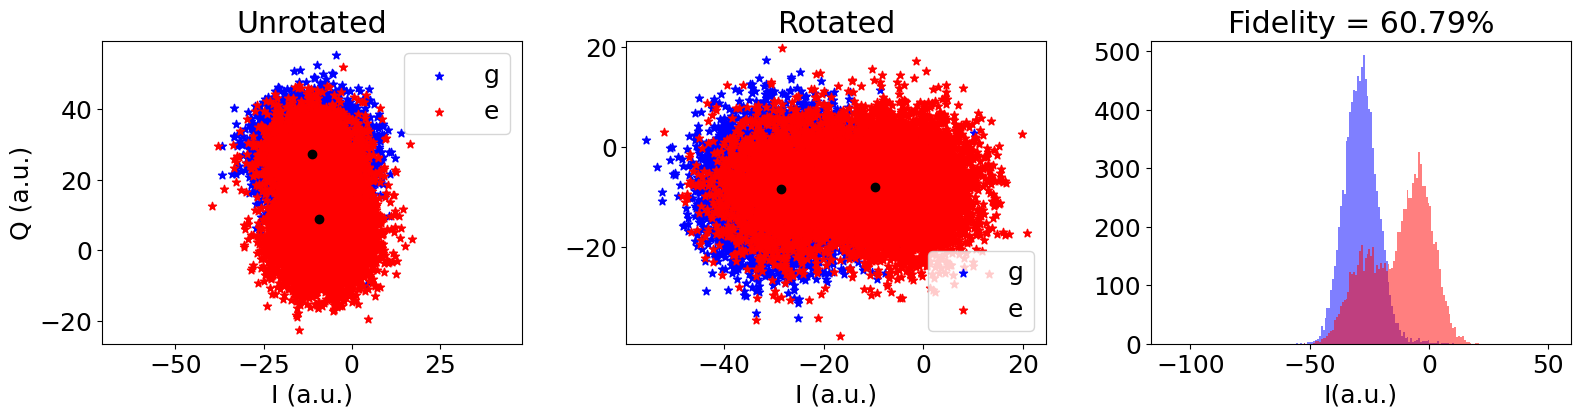

In [76]:
data = global_data_path + r"\00010_IQ_plot_Q0_2025-07-11.h5"

MUX = False
ef = False
with SlabFile(data, 'r') as f:
    I_g = array(f['I_g'])[0]
    Q_g = array(f['Q_g'])[0]
    I_e = array(f['I_e'])[0]
    Q_e = array(f['Q_e'])[0]
    if ef == True:
        I_f = array(f['I_f'])[0]
        Q_f = array(f['Q_f'])[0]
    config = f.attrs['config']
    config = json.loads(config)

pp.pprint(config)

print('\n data path:', data)

plt.title('IQ Plot')
plt.plot(I_g, Q_g, '.',label = 'g')
plt.plot(I_e, Q_e, '.',label = 'e')
if ef == True:
    plt.plot(I_f, Q_f, '.',label = 'f')
plt.xlabel('I')
plt.ylabel('Q')
plt.legend()
plt.axis('square')
plt.show()

fid, threshold, angle = hist(data=[I_g, Q_g, I_e, Q_e],  plot=True, ran=80)
print('Optimal fidelity after rotation = %.3f' % fid)

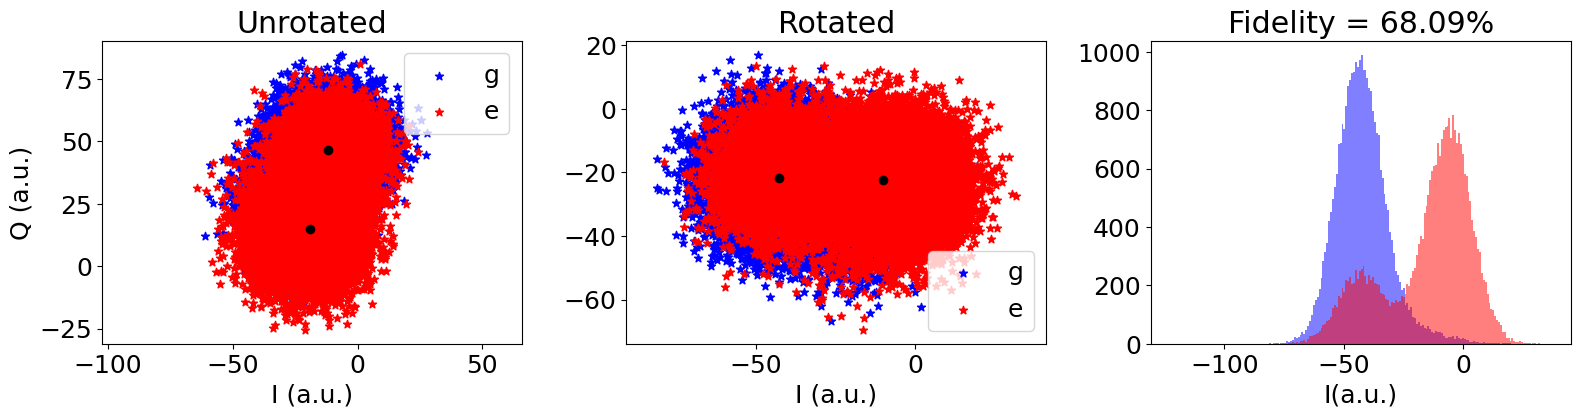
0.09
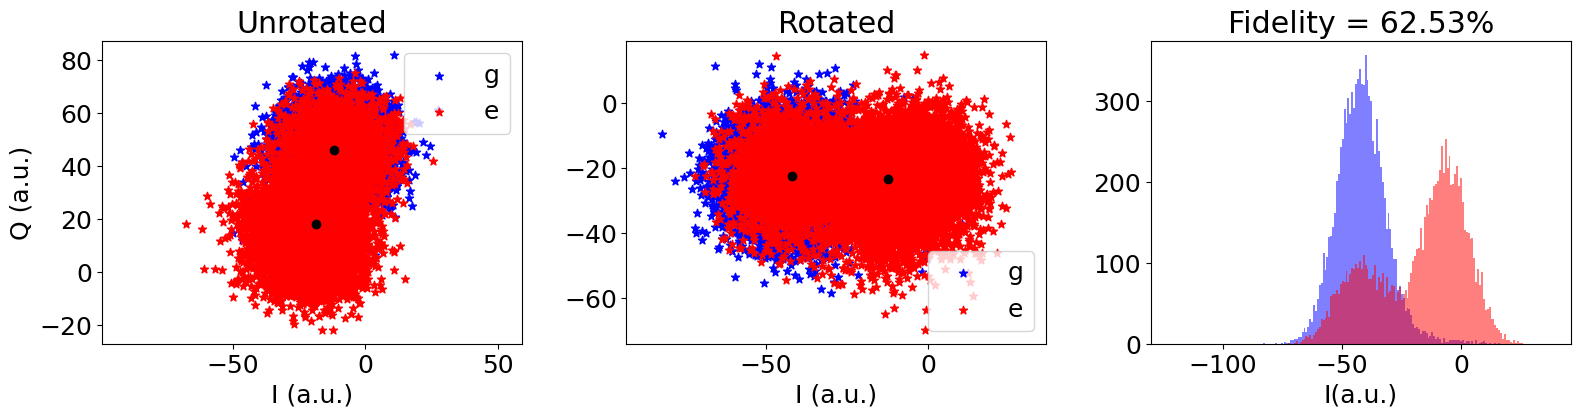
0.065
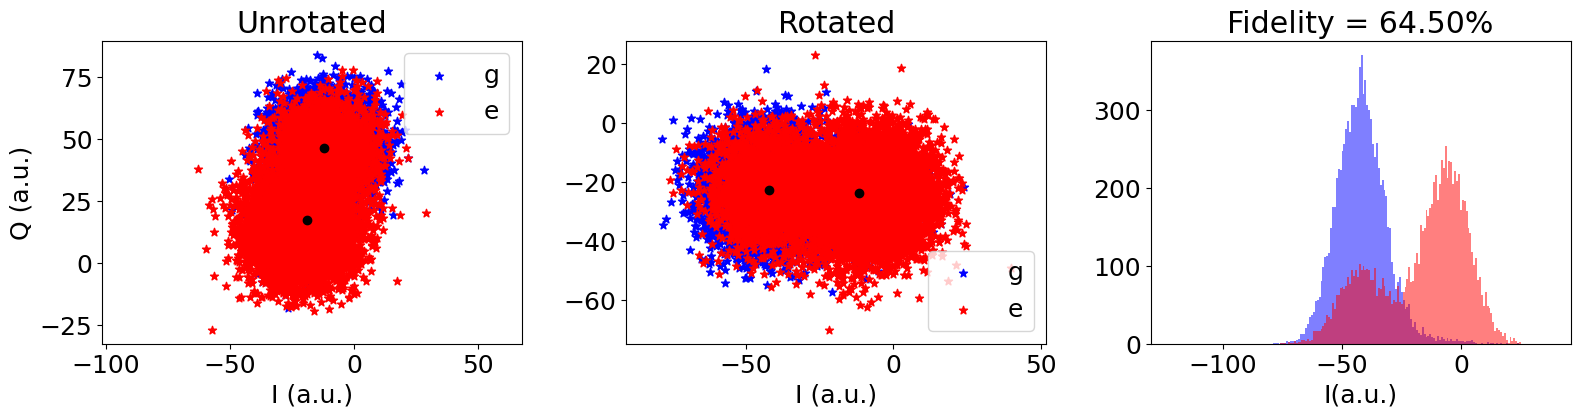

lower readout power
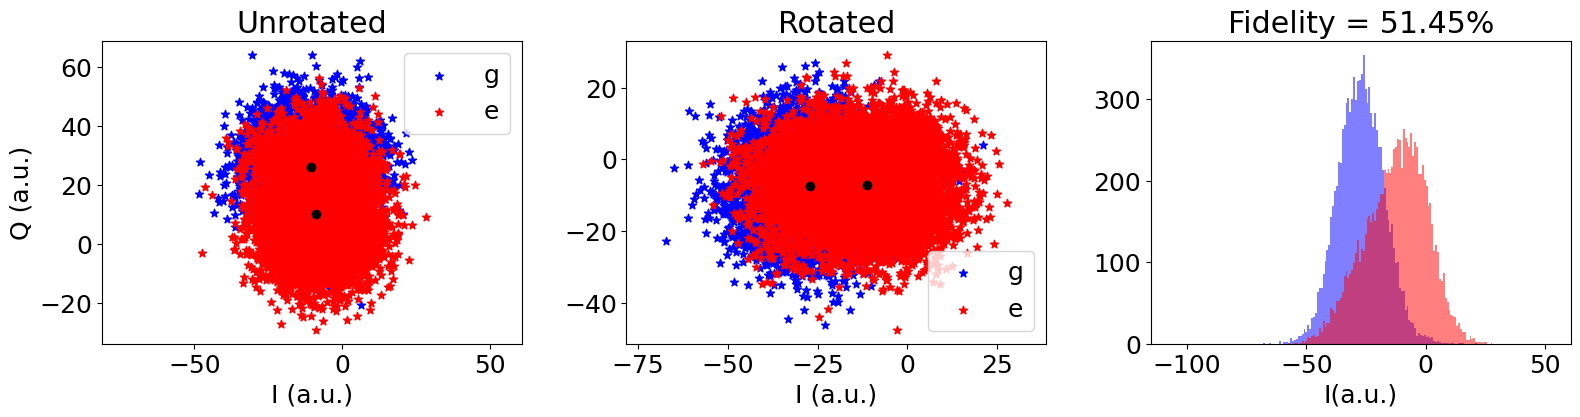
is this just a resolution issue, if we do a longer readout time..
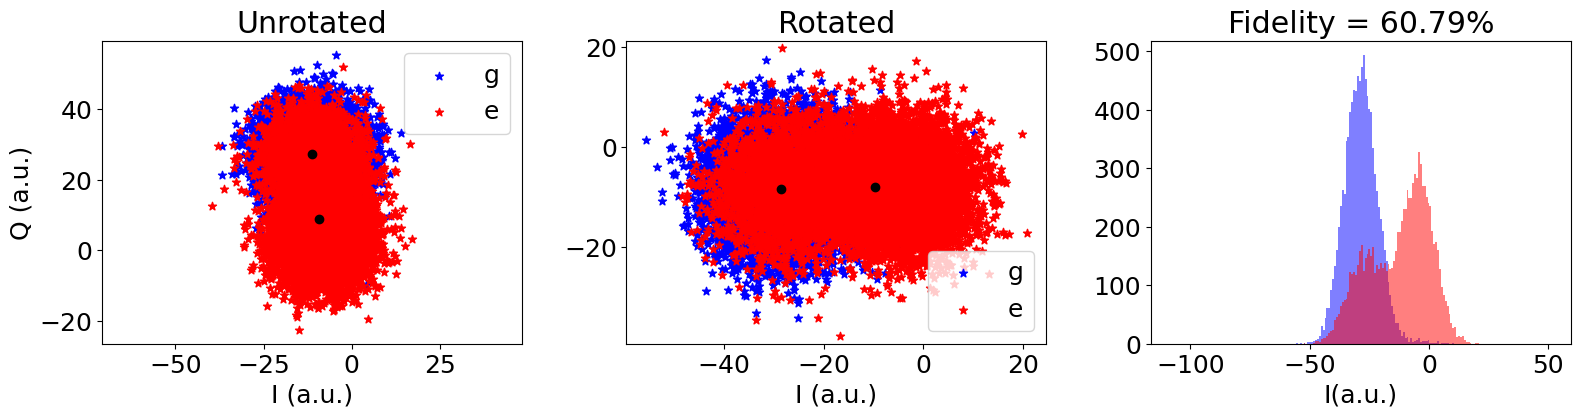
yeah the extra hump is still a weird issue
Definitely some kind of TLS or another kind of weird behavior...